<a href="https://colab.research.google.com/github/narayn02/BT-141-MAJOR-PROJECT/blob/main/Email_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)



nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [16]:
from google.colab import files

uploaded = files.upload()

Saving emails.csv to emails (1).csv


In [18]:
df = pd.read_csv("emails.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Dataset Shape: (5728, 2)
Columns: ['text', 'spam']


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [19]:
df = df[['text', 'spam']]

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (5728, 2)


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [20]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nLabel Values:")
print(df['spam'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB

Missing Values:
text    0
spam    0
dtype: int64

Duplicate Rows:
33

Label Values:
spam
0    4360
1    1368
Name: count, dtype: int64


In [21]:
df = df.dropna(subset=['text', 'spam'])

df = df.drop_duplicates()

df['text'] = df['text'].astype(str)

df['spam'] = pd.to_numeric(df['spam'], errors='coerce')

df = df.dropna(subset=['spam'])

df = df[df['spam'].isin([0, 1])]

df['spam'] = df['spam'].astype(int)

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (5695, 2)


In [22]:
print("Email Class Distribution:")

print(
    df['spam']
    .map({0: 'Ham', 1: 'Spam'})
    .value_counts()
)

Email Class Distribution:
spam
Ham     4327
Spam    1368
Name: count, dtype: int64


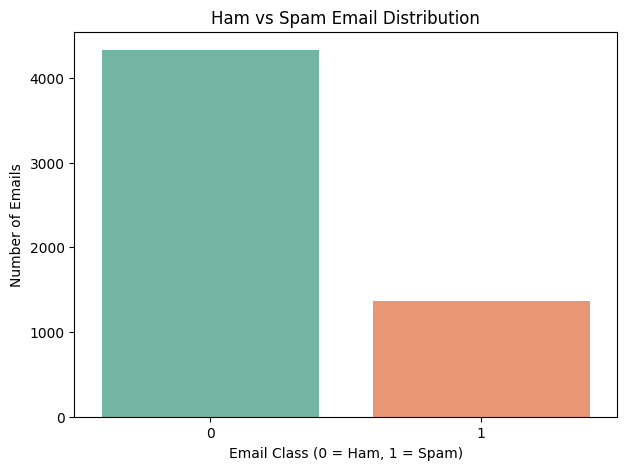

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='spam',
    hue='spam',
    order=[0, 1],
    palette='Set2',
    legend=False
)

plt.title("Ham vs Spam Email Distribution")
plt.xlabel("Email Class (0 = Ham, 1 = Spam)")
plt.ylabel("Number of Emails")

plt.show()

In [26]:
print("Label Mapping:")
print("0 = Ham / Not Spam")
print("1 = Spam")

print("\nUnique Labels:", sorted(df['spam'].unique()))

print(df[['text', 'spam']].head())

Label Mapping:
0 = Ham / Not Spam
1 = Spam

Unique Labels: [np.int64(0), np.int64(1)]
                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1


**TEXT PREPROCESSING FUNCTION**

In [27]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):

    text = str(text).lower()

    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    text = re.sub(r'\S+@\S+', '', text)

    text = re.sub(r'\d+', '', text)

    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    words = text.split()

    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


APPLY PREPROCESSING

In [28]:
df['clean_text'] = df['text'].apply(preprocess_text)

df[['text', 'clean_text']].head(10)

,text,clean_text
0,Subject: naturally irresistible your corporate...,subject natur irresist corpor ident lt realli ...
1,Subject: the stock trading gunslinger fanny i...,subject stock trade gunsling fanni merril muzo...
2,Subject: unbelievable new homes made easy im ...,subject unbeliev new home made easi im want sh...
3,Subject: 4 color printing special request add...,subject color print special request addit info...
4,"Subject: do not have money , get software cds ...",subject money get softwar cd softwar compat gr...
5,"Subject: great nnews hello , welcome to medzo...",subject great nnew hello welcom medzonlin sh g...
6,Subject: here ' s a hot play in motion homela...,subject hot play motion homeland secur invest ...
7,Subject: save your money buy getting this thin...,subject save money buy get thing tri ciall yet...
8,Subject: undeliverable : home based business f...,subject undeliver home base busi grownup messa...
9,Subject: save your money buy getting this thin...,subject save money buy get thing tri ciall yet...


In [29]:
X = df['clean_text']
y = df['spam']

print("Total Emails:", len(X))
print("Total Labels:", len(y))

Total Emails: 5695
Total Labels: 5695


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4556
Testing samples: 1139


**TF-IDF FEATURE EXTRACTION**

In [31]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (4556, 5000)
Testing TF-IDF Shape: (1139, 5000)


**NAIVE BAYES MODEL**

In [33]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes Classification Report:")

print(
    classification_report(
        y_test,
        nb_pred,
        labels=[0, 1],
        target_names=['Ham', 'Spam'],
        zero_division=0
    )
)

Naive Bayes Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       865
        Spam       0.98      0.96      0.97       274

    accuracy                           0.99      1139
   macro avg       0.98      0.98      0.98      1139
weighted avg       0.99      0.99      0.99      1139



**SVM MODEL**

In [34]:
svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("SVM Classification Report:")
print(
    classification_report(
        y_test,
        svm_pred,
        target_names=['Ham', 'Spam']
    )
)

SVM Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       865
        Spam       0.98      0.98      0.98       274

    accuracy                           0.99      1139
   macro avg       0.99      0.99      0.99      1139
weighted avg       0.99      0.99      0.99      1139



**RANDOM FOREST MODEL**

In [35]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest Classification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=['Ham', 'Spam']
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       865
        Spam       0.98      0.95      0.97       274

    accuracy                           0.99      1139
   macro avg       0.99      0.97      0.98      1139
weighted avg       0.99      0.99      0.98      1139



**MODEL COMPARISION TABLE**

In [37]:
results = []

models = {
    "Naive Bayes": nb_pred,
    "SVM": svm_pred,
    "Random Forest": rf_pred
}

for name, prediction in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1-Score": f1_score(y_test, prediction)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.985075,0.981273,0.956204,0.968577
1,SVM,0.990342,0.981685,0.978102,0.979890
2,Random Forest,0.985075,0.984906,0.952555,0.968460


**MODEL COMPARISION GRAPH**

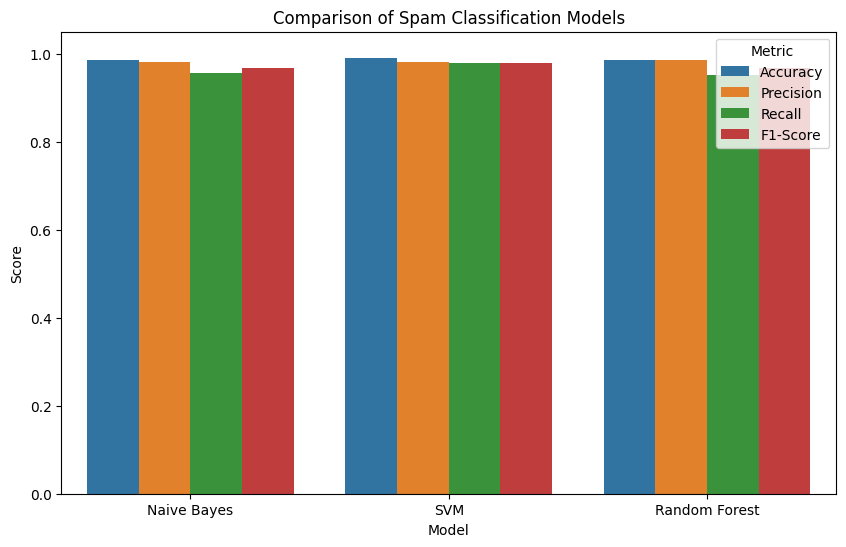

In [39]:
plt.figure(figsize=(10,6))

results_melted = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=results_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Comparison of Spam Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.show()

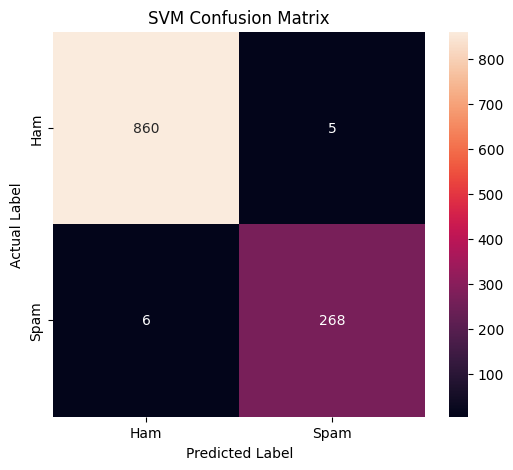

In [43]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()